# Fighter career statistics: exploratory plots

This notebook loads the fighter-level career statistics and analyzes only the selected predictors.

## Load data and set up analysis

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_PATH = Path("../data_clean/fighter_career_stats.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data_clean/fighter_career_stats.csv")

fighter_stats = pd.read_csv(DATA_PATH)

## Apply minimum fight filter

The notebook will be using min_total_fights = 2

In [2]:
MIN_TOTAL_FIGHTS = 2


filtered_fighter_stats = fighter_stats.loc[
    fighter_stats["total_fights"].ge(MIN_TOTAL_FIGHTS)
].copy()
print(
    f"Retained {len(filtered_fighter_stats):,} of {len(fighter_stats):,} fighters "
    f"with total_fights >= {MIN_TOTAL_FIGHTS}."
)

Retained 2,279 of 2,683 fighters with total_fights >= 2.


## Select predictors for analysis

In [3]:
selected_predictors = [
    "fight_quickness",
    "win_DEC_pct",
    "win_KO_TKO_pct",
    "win_SUB_pct",
    "CTRL_pct",
    "KD_per_min",
    "SUB_ATT_per_min",
    "REV_per_min",
    "SIG_STR_att_per_min",
    "TOTAL_STR_att_per_min",
    "TD_att_per_min",
    "HEAD_att_per_min",
    "LEG_att_per_min",
    "DISTANCE_att_per_min",
    "CLINCH_att_per_min",
    "GROUND_att_per_min"
]

# Restrict every downstream analysis to the selected predictors.
continuous_stats = (
    filtered_fighter_stats[selected_predictors]
    .replace([np.inf, -np.inf], np.nan)
)

## Correlations among predictors

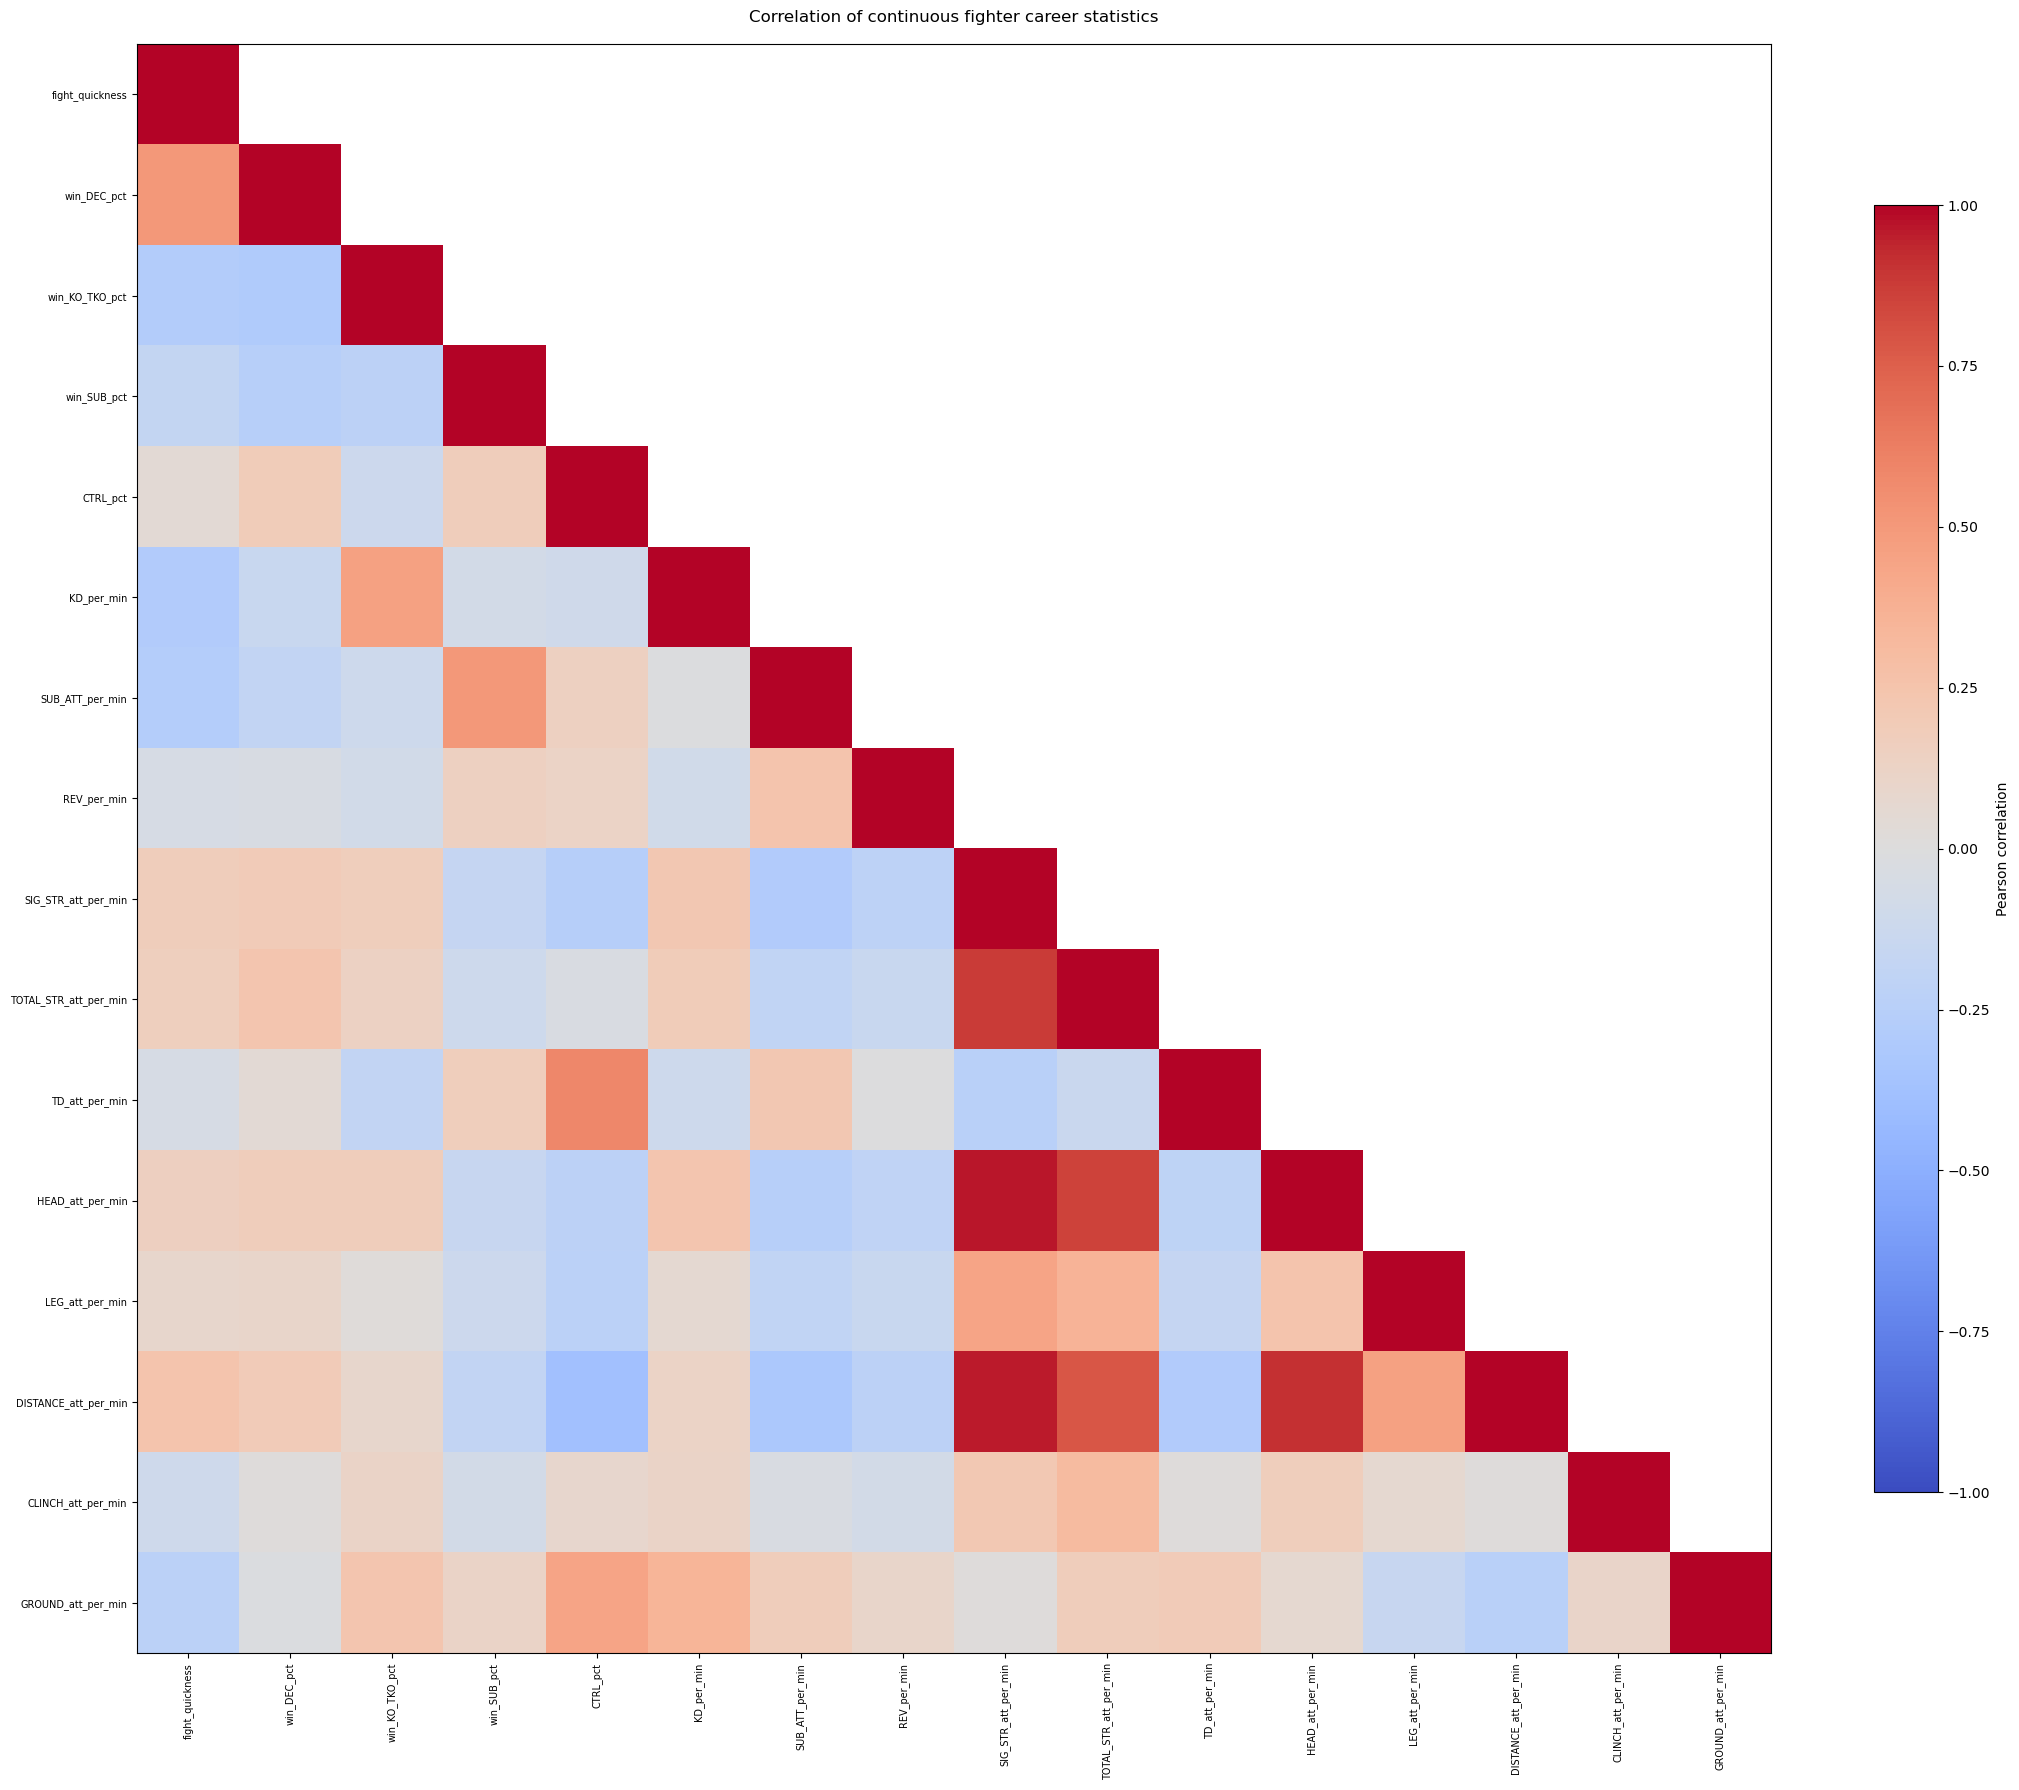

In [4]:
# Use only the selected predictors for all remaining analysis.
correlations = continuous_stats.corr()
upper_triangle = np.triu(np.ones_like(correlations, dtype=bool), k=1)

masked_correlations = correlations.mask(upper_triangle)
heatmap_cmap = plt.get_cmap("coolwarm").copy()
heatmap_cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(22, 18))
image = ax.imshow(
    masked_correlations,
    cmap=heatmap_cmap,
    vmin=-1,
    vmax=1,
    aspect="auto",
)
ax.set_xticks(np.arange(len(correlations.columns)))
ax.set_yticks(np.arange(len(correlations.index)))
ax.set_xticklabels(correlations.columns, rotation=90, fontsize=7)
ax.set_yticklabels(correlations.index, fontsize=7)
ax.minorticks_off()
ax.grid(False, which="both", axis="both")
ax.set_title("Correlation of continuous fighter career statistics", pad=16)
fig.colorbar(image, ax=ax, label="Pearson correlation", shrink=0.8)
plt.tight_layout()
plt.show()

### Top 10 most strongly correlated variable pairs

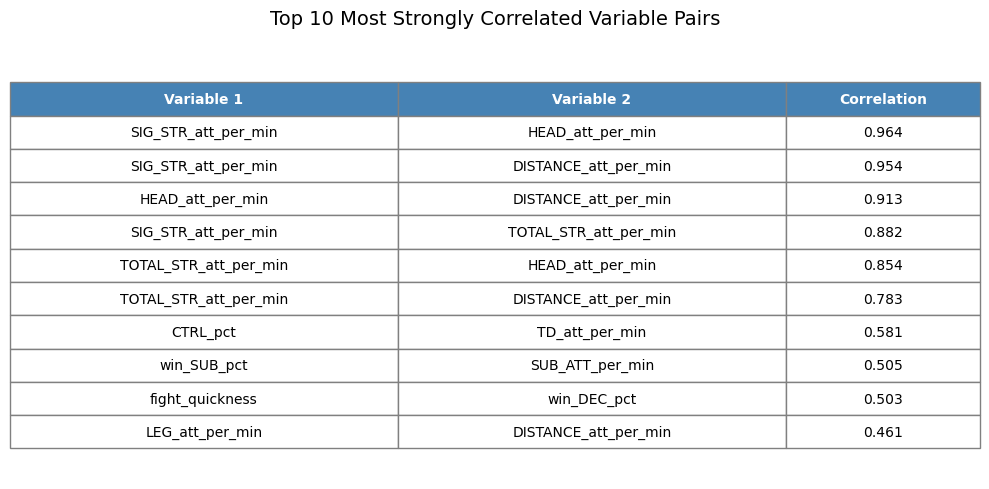

In [5]:
# Use the correlation matrix created above
upper_triangle = correlations.where(
    np.triu(np.ones(correlations.shape), k=1).astype(bool)
)

top_10_correlations = (
    upper_triangle
    .stack()
    .reset_index()
    .rename(columns={
        "level_0": "Variable 1",
        "level_1": "Variable 2",
        0: "Correlation"
    })
)

# Rank by absolute strength, but do not display absolute correlation
top_10_correlations = (
    top_10_correlations
    .assign(
        _sort_value=lambda df: df["Correlation"].abs()
    )
    .sort_values("_sort_value", ascending=False)
    .drop(columns="_sort_value")
    .head(10)
    .reset_index(drop=True)
)

# Format correlation values
table_data = top_10_correlations.copy()
table_data["Correlation"] = table_data["Correlation"].map(
    lambda x: f"{x:.3f}"
)

# Plot the table
fig, ax = plt.subplots(figsize=(10, 5))
ax.axis("off")

correlation_table = ax.table(
    cellText=table_data.values,
    colLabels=table_data.columns,
    cellLoc="center",
    loc="center",
    colWidths=[0.40, 0.40, 0.20]
)

correlation_table.auto_set_font_size(False)
correlation_table.set_fontsize(10)
correlation_table.scale(1, 1.8)

# Style table cells
for (row, column), cell in correlation_table.get_celld().items():
    cell.set_edgecolor("gray")

    if row == 0:
        cell.set_facecolor("steelblue")
        cell.set_text_props(color="white", weight="bold")

plt.title(
    "Top 10 Most Strongly Correlated Variable Pairs",
    fontsize=14,
    pad=20
)

plt.tight_layout()
plt.show()


## Offensive density plots

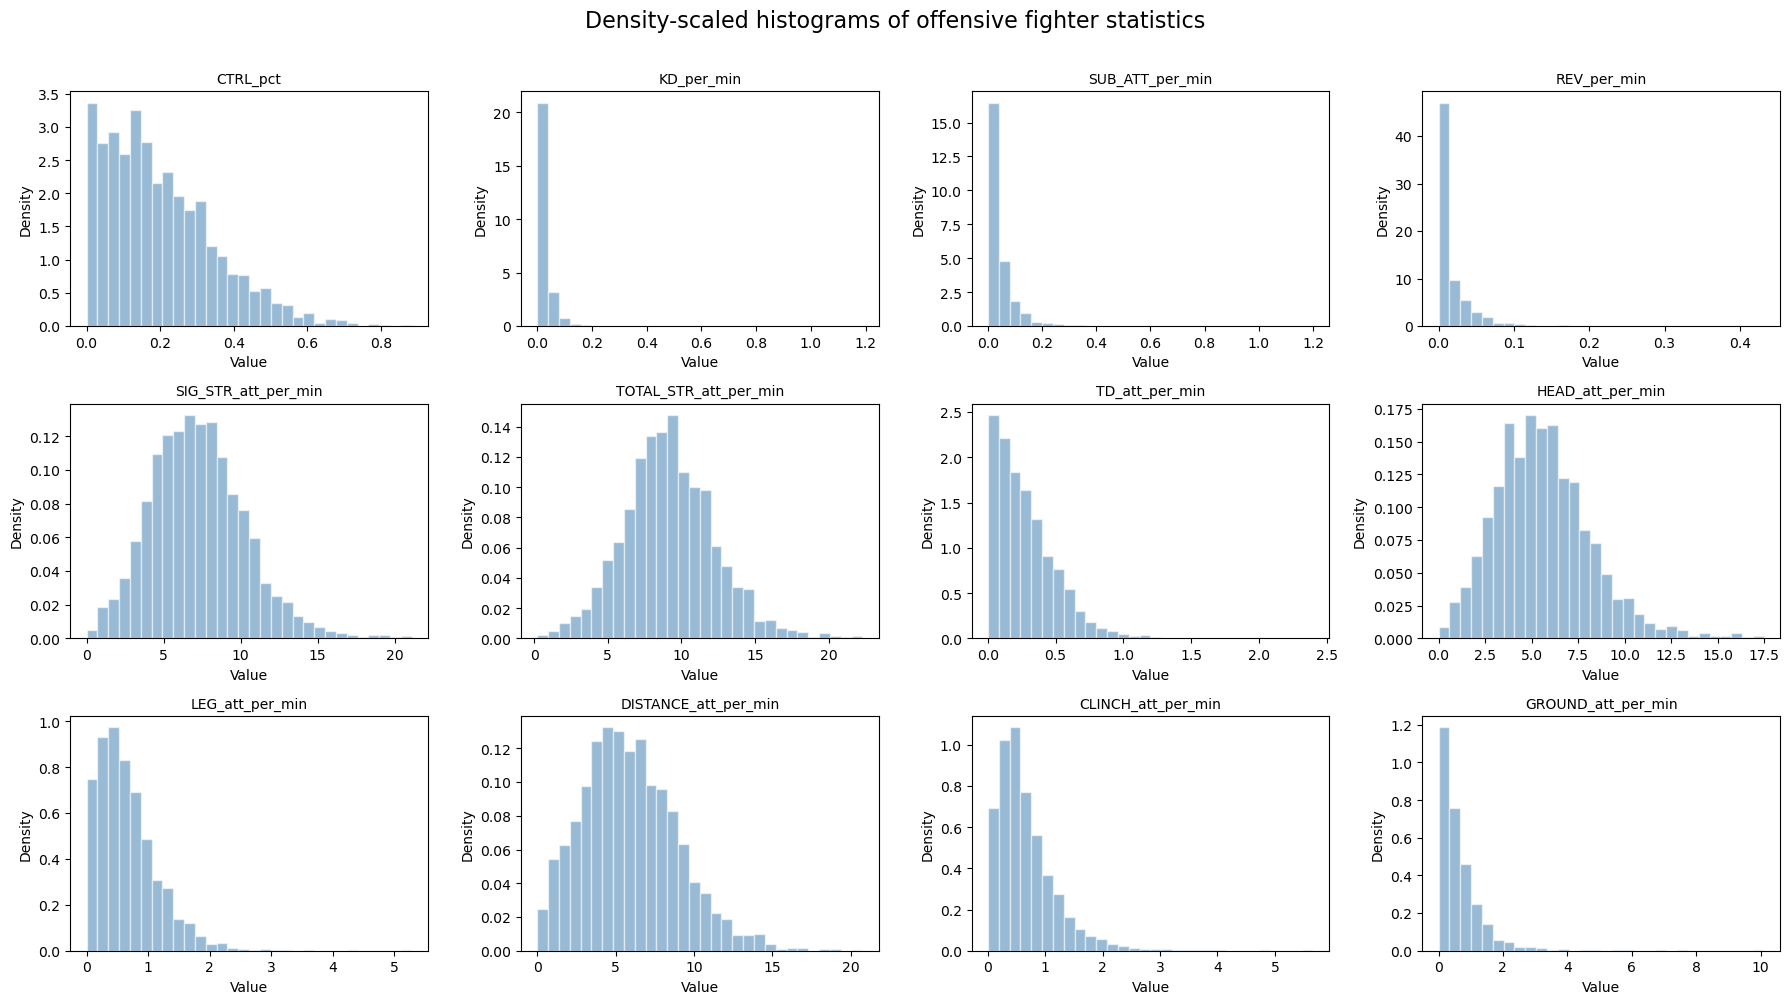

In [6]:
offensive_summary_columns = {
    "TOTAL_STR_acc",
    "SIG_STR_acc",
    "TD_acc",
    "CTRL_pct",
    "KD_per_min",
    "SUB_ATT_per_min",
    "REV_per_min",
}

offensive_columns = [
    column
    for column in continuous_stats.columns
    if (
        column in offensive_summary_columns
        or column.endswith(("_land_per_min", "_att_per_min"))
    )
    and "_opp_" not in column
    and "_absorbed_" not in column
]

n_columns = 4
n_rows = int(np.ceil(len(offensive_columns) / n_columns))
fig, axes = plt.subplots(n_rows, n_columns, figsize=(18, 3.3 * n_rows))
axes = np.asarray(axes).ravel()

for ax, column in zip(axes, offensive_columns):
    values = continuous_stats[column].dropna()
    if values.nunique() > 1:
        ax.hist(
            values,
            bins=30,
            density=True,
            color="steelblue",
            alpha=0.55,
            edgecolor="white",
        )
    elif not values.empty:
        ax.axvline(values.iloc[0], linewidth=2)
    ax.set_title(column, fontsize=10)
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")

for ax in axes[len(offensive_columns):]:
    ax.remove()

fig.suptitle("Density-scaled histograms of offensive fighter statistics", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## Variables with the highest share of zero values

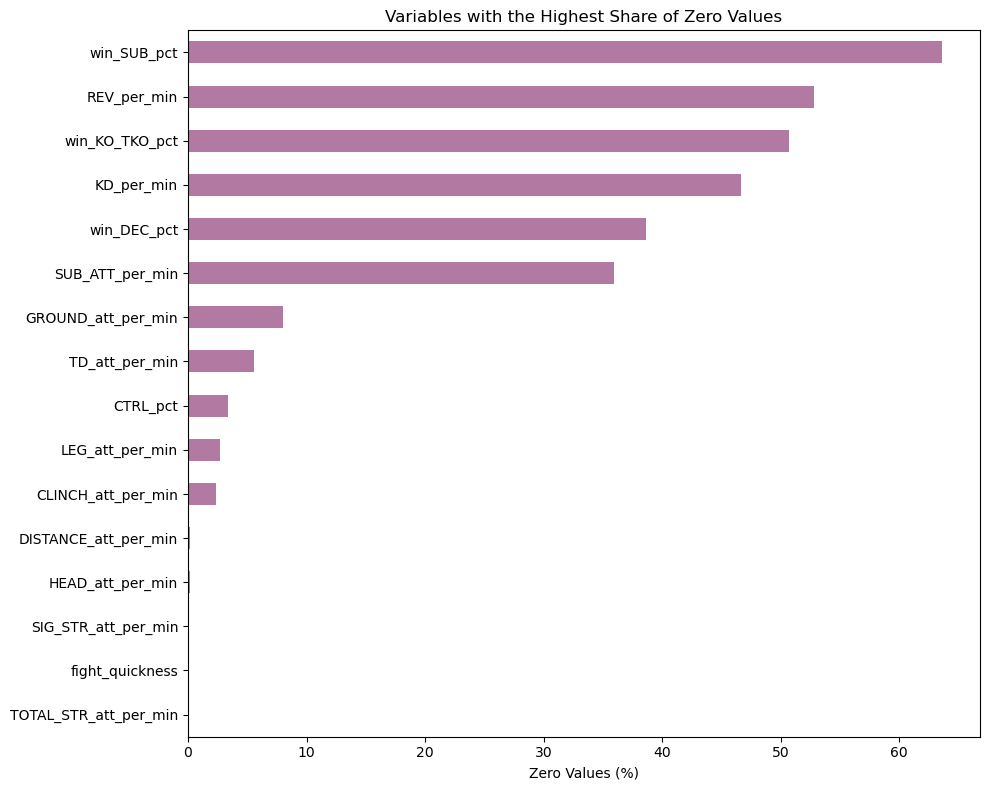

In [7]:
# 7. Variables with the highest share of zero values
# Use the filtered numerical variables from the notebook
features = continuous_stats.copy()

# Calculate the percentage of zero values for each variable
zero_rate = (
    features.eq(0)
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

# Create a summary table
zero_summary = pd.DataFrame({
    "zero_pct": zero_rate,
    "missing_cells": features.isna().sum(),
    "median": features.median()
}).sort_values(
    "zero_pct",
    ascending=False
)
# Plot the 20 variables with the highest percentage of zero values
plot_zero_rate = zero_rate.head(20).sort_values()

fig, ax = plt.subplots(figsize=(10, 8))

plot_zero_rate.plot(
    kind="barh",
    ax=ax,
    color="#b279a2"
)

ax.set_title("Variables with the Highest Share of Zero Values")
ax.set_xlabel("Zero Values (%)")
ax.set_ylabel("")

plt.tight_layout()
plt.show()

## Pairwise plots of offensive attempted rates

This matrix shows pairwise relationships among the offensive attempted-rate variables.

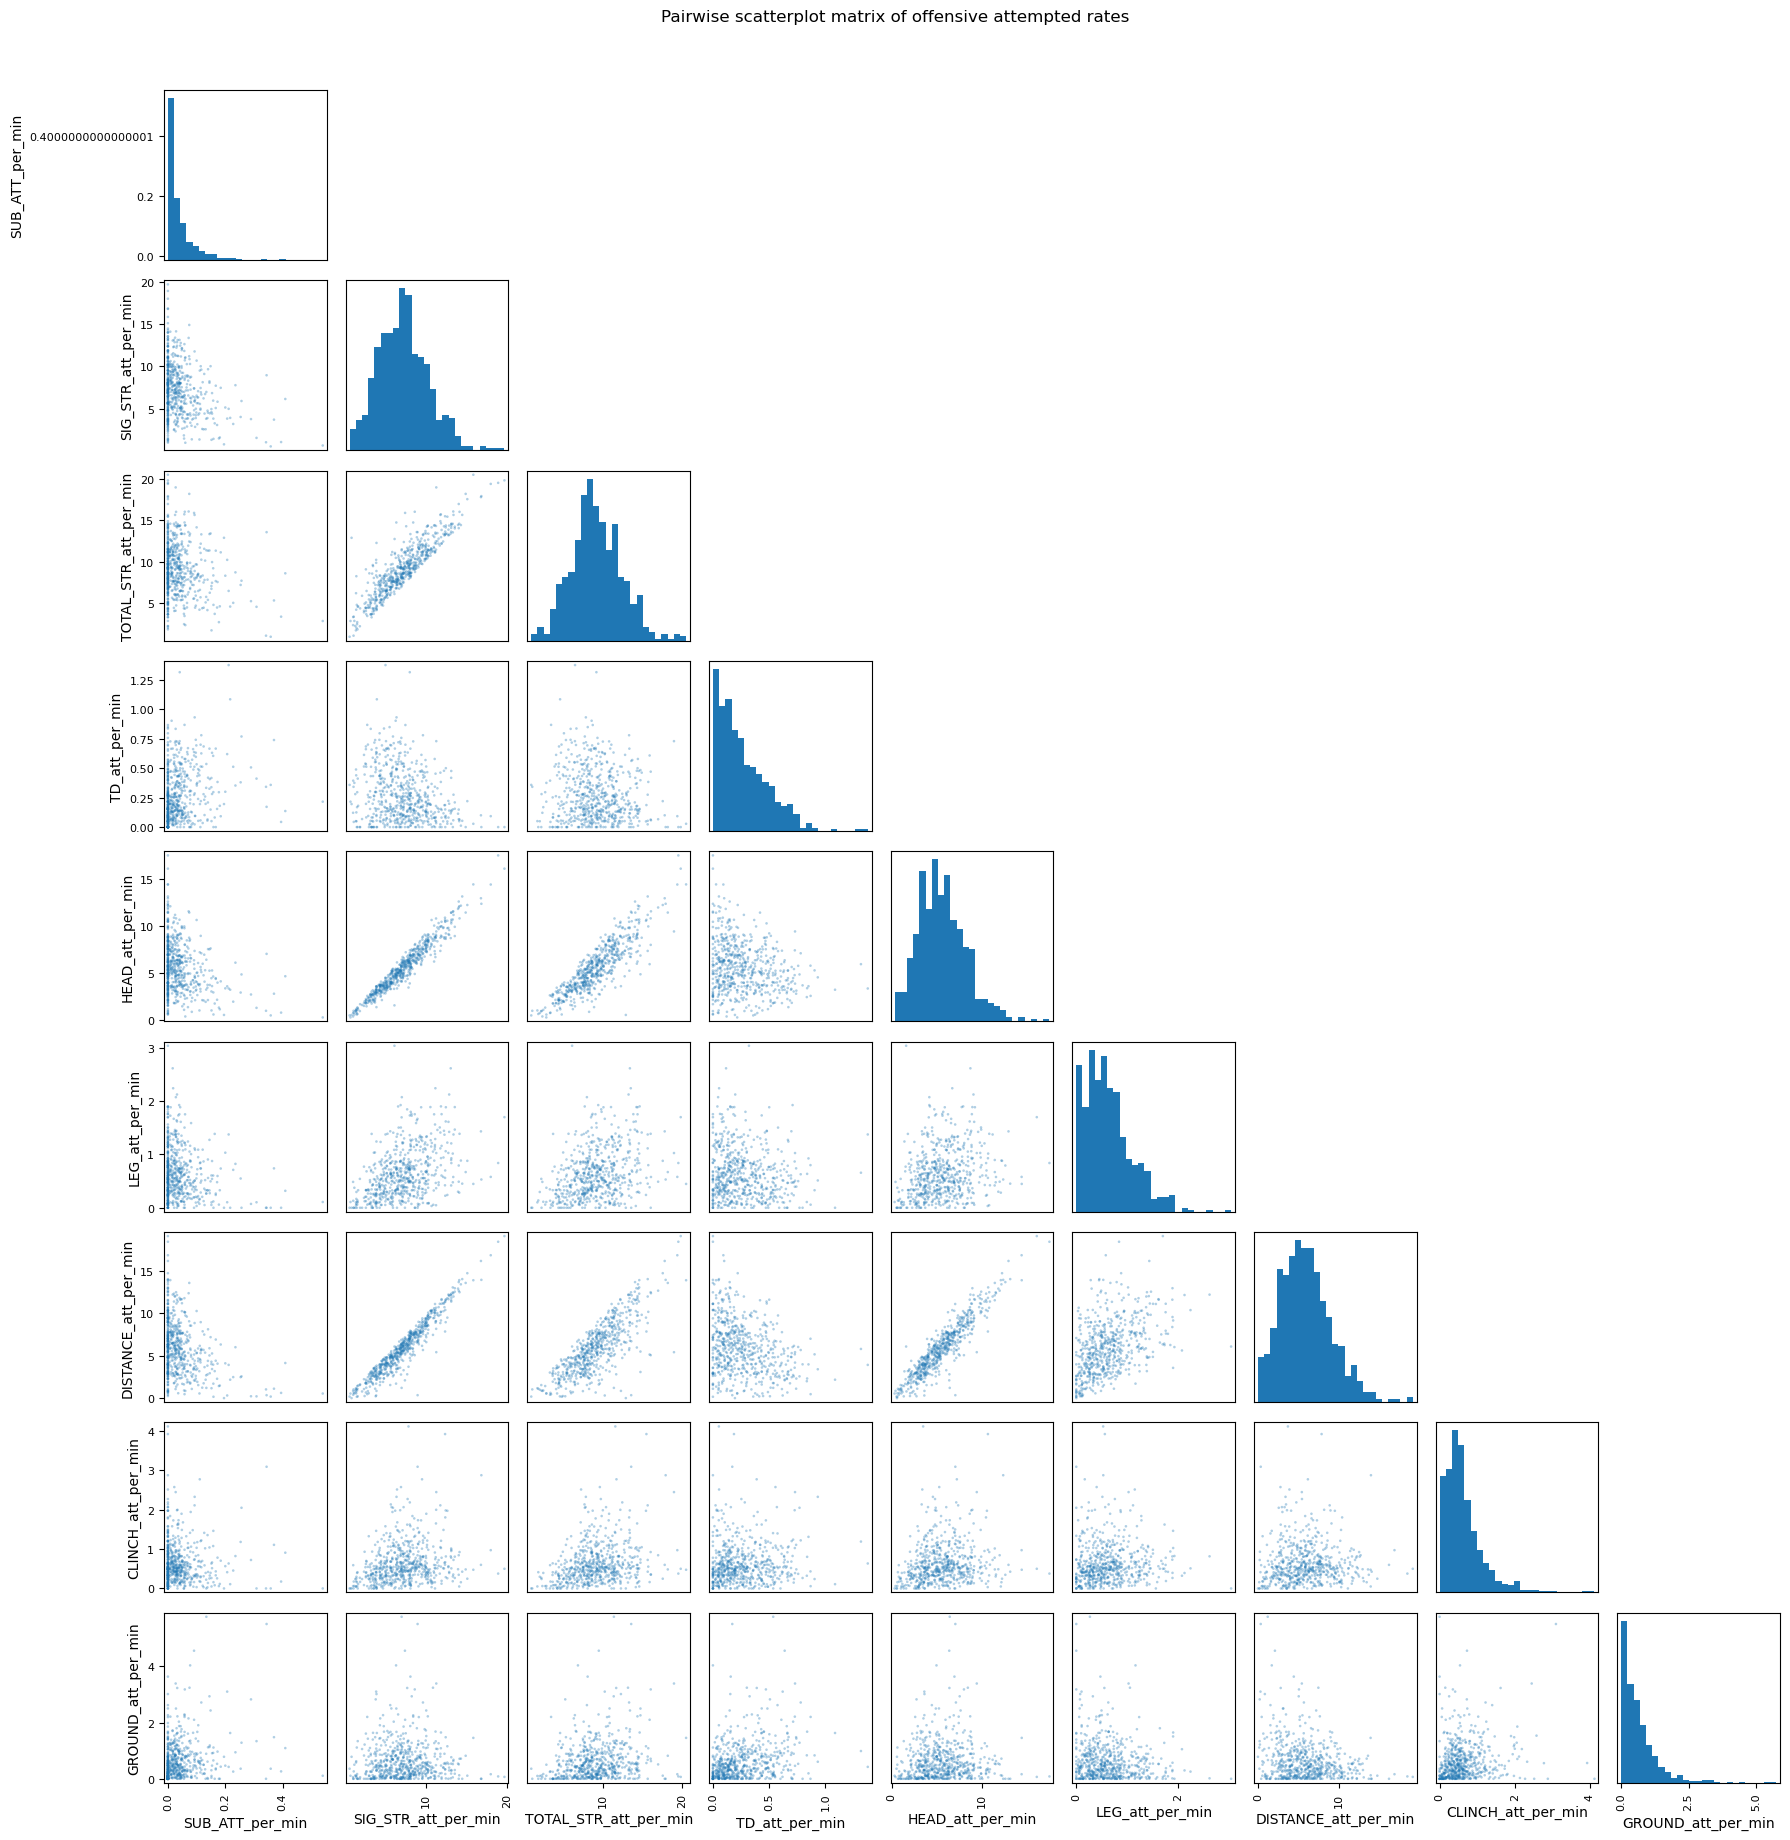

In [8]:
# 8. Pairwise plots of offensive attempted rates
# Limit the matrix to the attempted-rate metrics in the offensive histogram grid.
attempt_columns = [
    column for column in offensive_columns if column.lower().endswith("_att_per_min")
]

attempt_stats = continuous_stats[attempt_columns].dropna()
attempt_stats = attempt_stats.sample(
    n=min(600, len(attempt_stats)), random_state=42
)

def plot_scatter_matrix(data, title):
    axes = pd.plotting.scatter_matrix(
        data,
        alpha=0.35,
        s=14,
        diagonal="hist",
        hist_kwds={"bins": 25},
        figsize=(18, 18),
        edgecolors="none",
    )

    for row_index in range(axes.shape[0]):
        for column_index in range(axes.shape[1]):
            if column_index > row_index:
                axes[row_index, column_index].set_visible(False)

    figure = axes[0, 0].get_figure()
    figure.suptitle(title, y=1.02)
    figure.tight_layout()
    return figure

plot_scatter_matrix(
    attempt_stats,
    "Pairwise scatterplot matrix of offensive attempted rates",
)
plt.show()

## 9. PCA scree plot

This section standardizes the selected predictors and shows how much variation is explained by each principal component.

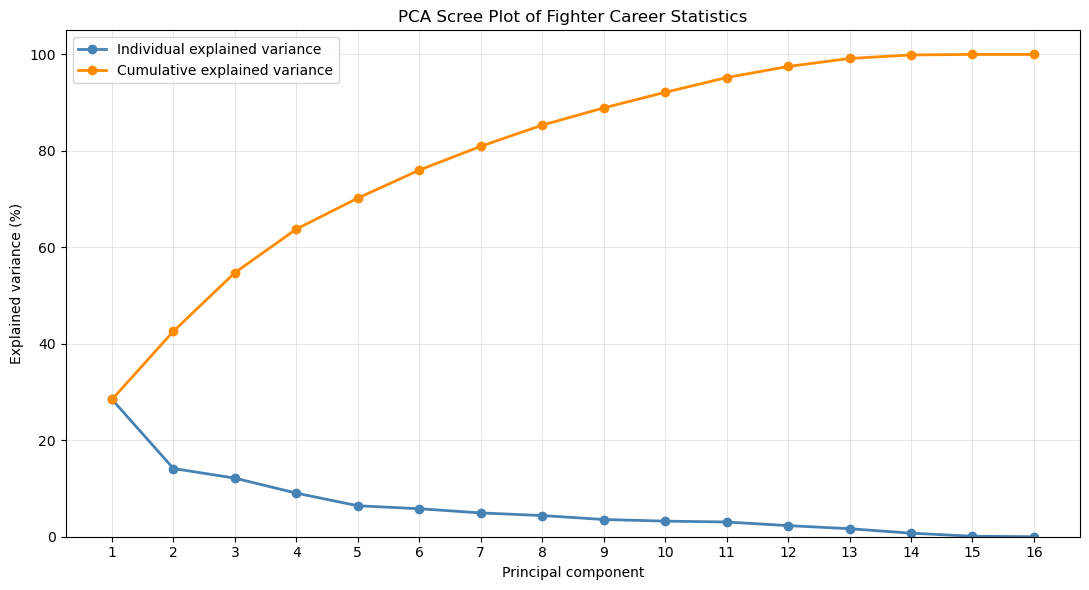

In [9]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Use only the selected predictors for PCA.
pca_data = continuous_stats.copy()

# Fill missing values before PCA so every fighter can be retained.
pca_imputed = SimpleImputer(strategy='mean').fit_transform(pca_data)

# Standardize variables because the career statistics use different scales.
pca_scaled = StandardScaler().fit_transform(pca_imputed)

pca = PCA()
pca.fit(pca_scaled)

component_numbers = np.arange(1, len(pca.explained_variance_ratio_) + 1)
explained_variance_pct = 100 * pca.explained_variance_ratio_
cumulative_variance_pct = np.cumsum(explained_variance_pct)

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(
    component_numbers,
    explained_variance_pct,
    marker='o',
    linewidth=2,
    color='steelblue',
    label='Individual explained variance'
)
ax.plot(
    component_numbers,
    cumulative_variance_pct,
    marker='o',
    linewidth=2,
    color='darkorange',
    label='Cumulative explained variance'
)
ax.set_xlabel('Principal component')
ax.set_ylabel('Explained variance (%)')
ax.set_title('PCA Scree Plot of Fighter Career Statistics')
ax.set_xticks(component_numbers)
ax.set_ylim(bottom=0)
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## Hopkins Statistic

The Hopkins statistic assesses whether the selected fighter predictors exhibit nonrandom spatial structure that may indicate clustering.

In [12]:
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# True = dimension-adjusted Hopkins
# False = standard unpowered Hopkins
DIMENSION_ADJUSTED = True


# Use only the selected predictors
hopkins_data = (
    continuous_stats
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# Standardize predictors before calculating distances
hopkins_data = StandardScaler().fit_transform(hopkins_data)


def calculate_hopkins(data, sample_size=100, random_state=None):
    rng = np.random.default_rng(random_state)

    n_rows, n_columns = data.shape
    sample_size = min(sample_size, n_rows // 2)

    # Randomly sample real observations
    real_indices = rng.choice(
        n_rows,
        size=sample_size,
        replace=False
    )

    real_sample = data[real_indices]

    # Distances from real observations to their nearest other real observation
    real_neighbors = NearestNeighbors(n_neighbors=2)
    real_neighbors.fit(data)

    real_distances = real_neighbors.kneighbors(
        real_sample,
        return_distance=True
    )[0][:, 1]

    # Generate artificial observations uniformly across observed ranges
    lower_bounds = data.min(axis=0)
    upper_bounds = data.max(axis=0)

    artificial_sample = rng.uniform(
        lower_bounds,
        upper_bounds,
        size=(sample_size, n_columns)
    )

    # Distances from artificial observations to nearest real observations
    artificial_neighbors = NearestNeighbors(n_neighbors=1)
    artificial_neighbors.fit(data)

    artificial_distances = artificial_neighbors.kneighbors(
        artificial_sample,
        return_distance=True
    )[0][:, 0]

    # Apply dimension adjustment if selected
    if DIMENSION_ADJUSTED:
        p = n_columns
        artificial_values = artificial_distances ** p
        real_values = real_distances ** p
    else:
        artificial_values = artificial_distances
        real_values = real_distances

    return (
        artificial_values.sum()
        / (
            artificial_values.sum()
            + real_values.sum()
        )
    )


# Repeat the calculation to assess stability
hopkins_scores = []

for repetition in range(10):
    score = calculate_hopkins(
        hopkins_data,
        sample_size=220, # setting sample size to 10%
        random_state=4322 + repetition
    )

    hopkins_scores.append(score)

hopkins_results = pd.DataFrame({
    "Repetition": np.arange(1, len(hopkins_scores) + 1),
    "Hopkins Statistic": hopkins_scores
})

display(hopkins_results)

version_label = (
    "dimension-adjusted"
    if DIMENSION_ADJUSTED
    else "standard unpowered"
)

print(f"Hopkins version: {version_label}")
print(f"Mean Hopkins statistic: {np.mean(hopkins_scores):.3f}")
print(f"Standard deviation: {np.std(hopkins_scores):.3f}")
if DIMENSION_ADJUSTED:
    print(f"Number of dimensions used: {hopkins_data.shape[1]}")

,Repetition,Hopkins Statistic
0,1,1.000000
1,2,1.000000
2,3,1.000000
3,4,1.000000
4,5,1.000000
5,6,1.000000
6,7,1.000000
7,8,1.000000
8,9,0.886255
9,10,1.000000


Hopkins version: dimension-adjusted
Mean Hopkins statistic: 0.989
Standard deviation: 0.034
Number of dimensions used: 16


Achieved really high Hopkins score of 0.911 average. 

Hopkins measures clustering tendency relative to a uniform spatial reference. Our high value indicates strong evidence of non-uniformity.

This could inidcate strong clustering tendencies, but not yet informs us how the clusters are formed. We will 
look at the geometry of the clusters through VAT.



## VAT (Visual Assessment of Tendency)

VAT reorders fighters according to similarity and displays their pairwise distances as a heatmap. Block-like patterns may indicate distinct groups.

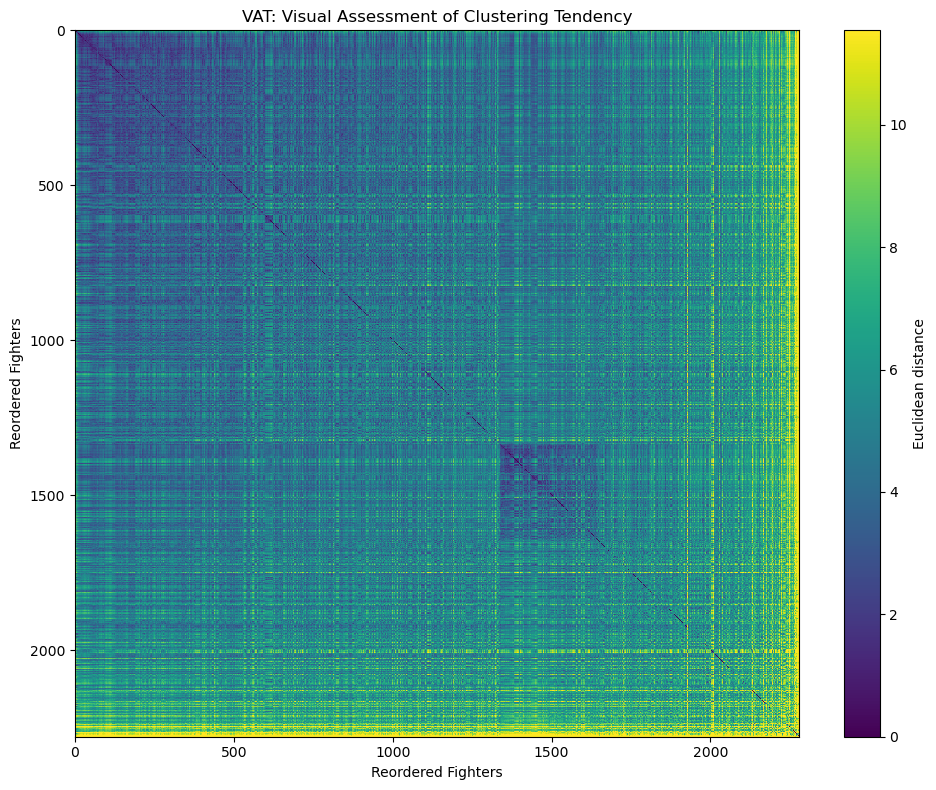

In [11]:
from scipy.spatial.distance import pdist, squareform
from sklearn.preprocessing import StandardScaler

# Use all selected predictors
vat_data = (
    continuous_stats
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
)

# Standardize predictors before calculating distances
vat_scaled = StandardScaler().fit_transform(vat_data)

# Calculate pairwise Euclidean distances
distance_matrix = squareform(
    pdist(vat_scaled, metric="euclidean")
)

# Reorder observations using the VAT ordering procedure
def vat_order(distances):
    n_observations = distances.shape[0]

    order = np.empty(n_observations, dtype=int)
    remaining = np.ones(n_observations, dtype=bool)

    # Start with the observation having the largest total distance
    first_index = np.unravel_index(
        np.argmax(distances), distances.shape
    )[0]
    order[0] = first_index
    remaining[first_index] = False

    # Track each remaining observation's distance to the selected set
    minimum_distances = distances[first_index].copy()
    minimum_distances[first_index] = np.inf

    for position in range(1, n_observations):
        next_index = np.argmin(
            np.where(remaining, minimum_distances, np.inf)
        )

        order[position] = next_index
        remaining[next_index] = False

        minimum_distances = np.minimum(
            minimum_distances,
            distances[next_index]
        )

    return order


vat_indices = vat_order(distance_matrix)

# Reorder the distance matrix
reordered_distances = distance_matrix[
    np.ix_(vat_indices, vat_indices)
]

# Plot the VAT heatmap
fig, ax = plt.subplots(figsize=(10, 8))


# Set color bar limits to 99th percentile, since 100 gives outlier
image = ax.imshow(
    reordered_distances,
    cmap="viridis",
    vmin=0,
    vmax=np.percentile(reordered_distances, 99),
    aspect="auto",
    interpolation="nearest"
)

ax.set_title("VAT: Visual Assessment of Clustering Tendency")
ax.set_xlabel("Reordered Fighters")
ax.set_ylabel("Reordered Fighters")
ax.grid(False)

fig.colorbar(
    image,
    ax=ax,
    label="Euclidean distance"
)

plt.tight_layout()
plt.show()

Not many distinct blocks are present from a visual test. We see one in the top corner and one near the center bottom right. 

VAT is not able to clearly establish multiple discrete styles within the data. 